## Netflix Analysis

In [136]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np
import zipfile

In [137]:
# open .zip file in dataset folder
with zipfile.ZipFile("dataset/archive.zip", "r") as archive:
    # extracting data to the dataset folder
    files = archive.extractall("dataset")    

In [138]:
df_netflix_data = pd.read_csv("dataset/Netflix Dataset.csv")

In [139]:
df_netflix_data.head()

,Show_Id,Category,Title,Director,Cast,Country,Release_Date,Rating,Duration,Type,Description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,07:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [140]:
df_netflix_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7789 entries, 0 to 7788
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Show_Id       7789 non-null   str  
 1   Category      7789 non-null   str  
 2   Title         7789 non-null   str  
 3   Director      5401 non-null   str  
 4   Cast          7071 non-null   str  
 5   Country       7282 non-null   str  
 6   Release_Date  7779 non-null   str  
 7   Rating        7782 non-null   str  
 8   Duration      7789 non-null   str  
 9   Type          7789 non-null   str  
 10  Description   7789 non-null   str  
dtypes: str(11)
memory usage: 669.5 KB


In [141]:
df_netflix_data.describe()

,Show_Id,Category,Title,Director,Cast,Country,Release_Date,Rating,Duration,Type,Description
count,7789,7789,7789,5401,7071,7282,7779,7782,7789,7789,7789
unique,7787,2,7787,4050,6831,681,1565,14,216,492,7769
top,s684,Movie,Backfire,"Raúl Campos, Jan Suter",David Attenborough,United States,"January 1, 2020",TV-MA,1 Season,Documentaries,Multiple women report their husbands as missin...
freq,2,5379,2,18,18,2556,118,2865,1608,334,3


### Q1: For 'House of Cards', what is the Show Id and Who is the Director of this show ?

In [142]:
directors = df_netflix_data.loc[df_netflix_data['Title'] == 'House of Cards', 'Director'].str.split(',').explode().str.strip()
index = df_netflix_data.loc[df_netflix_data['Title'] == 'House of Cards', 'Show_Id']
print('--- Index ---')
print(index.item())

print('\n--- Directors ---')
for dir in directors:
    print(dir)



--- Index ---
s2833

--- Directors ---
Robin Wright
David Fincher
Gerald McRaney
John David Coles
David Manson


### Q2: In which year the highest number of the TV Shows & Movies were released ? Show with Bar Graph.

In [143]:
df_netflix_data['Release_Date'] = df_netflix_data['Release_Date'].astype('datetime64[us]')

In [144]:
df_netflix_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7789 entries, 0 to 7788
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Show_Id       7789 non-null   str           
 1   Category      7789 non-null   str           
 2   Title         7789 non-null   str           
 3   Director      5401 non-null   str           
 4   Cast          7071 non-null   str           
 5   Country       7282 non-null   str           
 6   Release_Date  7779 non-null   datetime64[us]
 7   Rating        7782 non-null   str           
 8   Duration      7789 non-null   str           
 9   Type          7789 non-null   str           
 10  Description   7789 non-null   str           
dtypes: datetime64[us](1), str(10)
memory usage: 669.5 KB


In [145]:
df_netflix_data.head()

,Show_Id,Category,Title,Director,Cast,Country,Release_Date,Rating,Duration,Type,Description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,2020-08-14,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,07:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,2016-12-23,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,2018-12-20,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,2017-11-16,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,2020-01-01,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [146]:
df_netflix_data['Release_Date'].dt.year

0       2020.0
1       2016.0
2       2018.0
3       2017.0
4       2020.0
         ...  
7784    2020.0
7785    2019.0
7786    2020.0
7787    2020.0
7788    2020.0
Name: Release_Date, Length: 7789, dtype: float64

In [147]:
df_netflix_data['Release_Year'] = df_netflix_data['Release_Date'].dt.year
df_netflix_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7789 entries, 0 to 7788
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Show_Id       7789 non-null   str           
 1   Category      7789 non-null   str           
 2   Title         7789 non-null   str           
 3   Director      5401 non-null   str           
 4   Cast          7071 non-null   str           
 5   Country       7282 non-null   str           
 6   Release_Date  7779 non-null   datetime64[us]
 7   Rating        7782 non-null   str           
 8   Duration      7789 non-null   str           
 9   Type          7789 non-null   str           
 10  Description   7789 non-null   str           
 11  Release_Year  7779 non-null   float64       
dtypes: datetime64[us](1), float64(1), str(10)
memory usage: 730.3 KB


In [148]:
df_netflix_data['Release_Year'] = df_netflix_data['Release_Year'].astype('Int64')

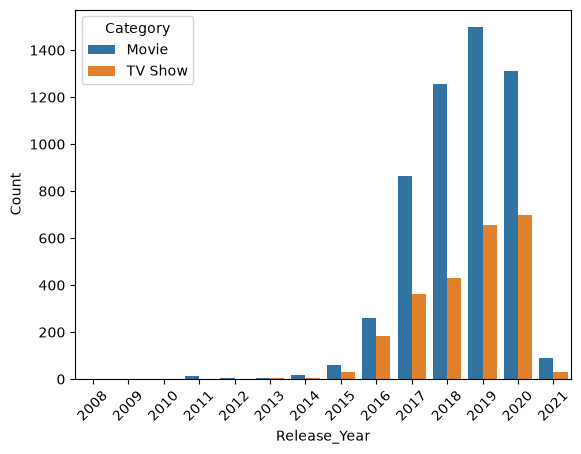

In [149]:
counts = df_netflix_data.groupby(['Release_Year', 'Category']).size().reset_index(name='Count')
sb.barplot(counts, x='Release_Year', y='Count', hue='Category')
plt.xticks(rotation=45)
plt.show()

### Q3:  How many Movies & TV Shows are in the dataset ? Show with Bar Graph.

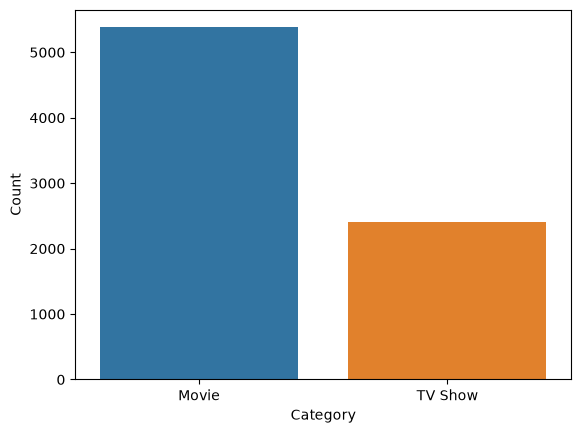

In [150]:
count = df_netflix_data.groupby(['Category']).size().reset_index(name='Count')

sb.barplot(count, x='Category', y='Count', hue='Category')
plt.show()

### Q4: Show all the Movies that were released in year 2015

In [151]:
df_netflix_data.loc[(df_netflix_data['Release_Year'] == 2015) & (df_netflix_data['Category'] == 'Movie')].sort_values('Release_Date')


,Show_Id,Category,Title,Director,Cast,Country,Release_Date,Rating,Duration,Type,Description,Release_Year
2946,s2947,Movie,Iliza Shlesinger: Freezing Hot,NaN,Iliza Shlesinger,NaN,2015-01-23,TV-MA,72 min,Stand-Up Comedy,Smart and brazen comedian Iliza Shlesinger app...,2015
7436,s7435,Movie,Virunga: Gorillas in Peril,NaN,NaN,United States,2015-02-13,TV-14,29 min,Documentaries,The team behind the searing documentary reveal...,2015
5826,s5826,Movie,Stop at Nothing: The Lance Armstrong Story,Alex Holmes,NaN,"Australia, United Kingdom, United States, New ...",2015-02-15,NR,100 min,"Documentaries, International Movies, Sports Mo...",An athlete dupes the world with his tale of mi...,2015
5087,s5087,Movie,Ralphie May: Unruly,John Asher,Ralphie May,United States,2015-02-27,TV-MA,83 min,Stand-Up Comedy,"Filmed in front of a raucous crowd, comedian R...",2015
4345,s4346,Movie,My Own Man,David Sampliner,David Sampliner,United States,2015-03-06,TV-MA,82 min,Documentaries,When a man discovers he will be the father to ...,2015
648,s649,Movie,Aziz Ansari Live at Madison Square Garden,Aziz Ansari,Aziz Ansari,United States,2015-03-06,TV-MA,58 min,Stand-Up Comedy,"Stand-up comedian and TV star Aziz Ansari (""Pa...",2015
3958,s3959,Movie,Marvel & ESPN Films Present: 1 of 1: Genesis,Eric Drath,"Manny Pacquiao, Michael Smith, Tony Hawk, Esth...",NaN,2015-03-15,TV-PG,77 min,"Documentaries, Sports Movies",This documentary explores the connections betw...,2015
1352,s1353,Movie,Chris D'Elia: Incorrigible,Bill D'Elia,Chris D'Elia,United States,2015-04-17,TV-MA,84 min,Stand-Up Comedy,Stand-up comedian Chris D'Elia covers everythi...,2015
5312,s5312,Movie,Russell Madness,Robert Vince,"David Milchard, John Ratzenberger, Will Sasso,...",United States,2015-05-10,PG,93 min,"Children & Family Movies, Comedies, Sports Movies",A spunky terrier named Russell with serious wr...,2015
7105,s7104,Movie,Tinker Bell and the Legend of the NeverBeast,Steve Loter,"Ginnifer Goodwin, Mae Whitman, Rosario Dawson,...",United States,2015-05-17,G,78 min,Children & Family Movies,When suspicious scout fairies scheme to captur...,2015


### Q5: Show only the Titles of all TV Shows that were released in India only.

In [152]:
titles = df_netflix_data.loc[(df_netflix_data['Country'] == 'India') & (df_netflix_data['Category'] == 'TV Show'), 'Title'].explode()
print('--- Titles From India ---')
for t in titles:
    print(t)

--- Titles From India ---
21 Sarfarosh: Saragarhi 1897
7 (Seven)
Agent Raghav
Akbar Birbal
Anjaan: Rural Myths
Anjaan: Special Crimes Unit
Bad Boy Billionaires: India
Badalte Rishton Ki Dastaan
Bard of Blood
Betaal
Bh Se Bhade
Bhaag Beanie Bhaag
Bhaage Re Mann
Chhota Bheem
ChuChu TV Nursery Rhymes & Kids Songs (Hindi)
Classic Legends
College Romance
Cricket Fever: Mumbai Indians
Darr Sabko Lagta Hai
Delhi Crime
Devlok with Devdutt Pattanaik
Dharmakshetra
Engineering Girls
Fabulous Lives of Bollywood Wives
Fear Files... Har Mod Pe Darr
Gabru: Hip Hop Revolution
Gangs of Hassepur
GHOUL
Girls Hostel
Hasmukh
Inmates
Jamtara - Sabka Number Ayega
Jhansi Ki Rani
Khan: No. 1 Crime Hunter
Khelti Hai Zindagi Aankh Micholi
Khotey Sikkey
Ladies Up
Leila
Little Singham
Little Things
Maharakshak Devi
Maharakshak: Aryan
Mahi Way
Masaba Masaba
Midnight Misadventures With Mallika Dua
Mighty Little Bheem: Diwali
Mighty Little Bheem: Festival of Colors
Mighty Little Bheem: Kite Festival
Mismatched
Paava 

### Q6: Show Top 10 Directors, who gave the highest number of TV Shows & Movies to Netflix ?

In [153]:
directors = df_netflix_data['Director'].dropna()

In [154]:
directors = directors.str.split(',').explode().str.strip()

In [155]:
counts = directors.value_counts().nlargest(10)

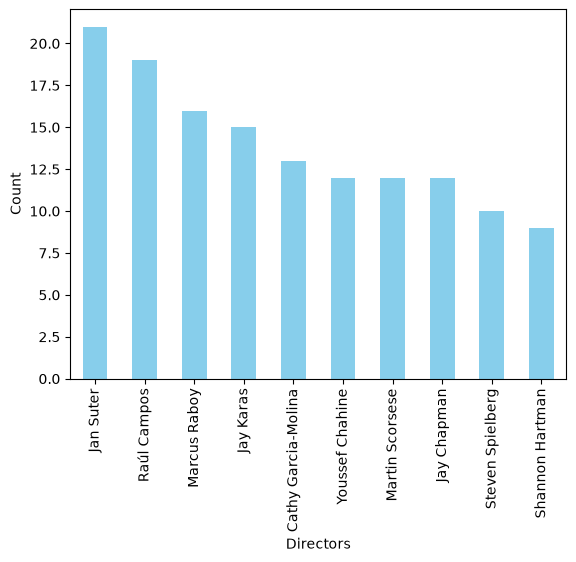

In [156]:
counts.plot(kind='bar', color='skyblue')
plt.xlabel('Directors')
plt.ylabel('Count')
plt.show()

### Q7:  Show all the Records, where "Category is Movie and Type is Comedies" or "Country is United Kingdom".

In [ ]:
df_netflix_data_copy = df_netflix_data.copy()
df_netflix_data_copy.loc[(df_netflix_data_copy['Type'].str.contains("Comedies", na=False)) & (df_netflix_data_copy['Category'] == 'Movie') | (df_netflix_data_copy['Country'] == "United Kingdom")]

,Show_Id,Category,Title,Director,Cast,Country,Release_Date,Rating,Duration,Type,Description,Release_Year
18,s19,Movie,15-Aug,Swapnaneel Jayakar,"Rahul Pethe, Mrunmayee Deshpande, Adinath Koth...",India,2019-03-29,TV-14,124 min,"Comedies, Dramas, Independent Movies","On India's Independence Day, a zany mishap in ...",2019
19,s20,Movie,'89,NaN,"Lee Dixon, Ian Wright, Paul Merson",United Kingdom,2018-05-16,TV-PG,87 min,Sports Movies,"Mixing old footage with interviews, this is th...",2018
33,s34,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,2017-09-08,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...,2017
34,s35,Movie,#Roxy,Michael Kennedy,"Jake Short, Sarah Fisher, Booboo Stewart, Dann...",Canada,2019-04-10,TV-14,105 min,"Comedies, Romantic Movies",A teenage hacker with a huge nose helps a cool...,2019
36,s37,Movie,#Selfie,Cristina Jacob,"Flavia Hojda, Crina Semciuc, Olimpia Melinte, ...",Romania,2019-06-01,TV-MA,125 min,"Comedies, Dramas, International Movies","Two days before their final exams, three teen ...",2019
...,...,...,...,...,...,...,...,...,...,...,...,...
7766,s7765,Movie,Zero,Aanand Rai,"Shah Rukh Khan, Anushka Sharma, Katrina Kaif, ...",India,2019-05-21,TV-14,159 min,"Comedies, Dramas, International Movies",Through his relationships with two wildly diff...,2019
7771,s7770,Movie,Zindagi Na Milegi Dobara,Zoya Akhtar,"Hrithik Roshan, Abhay Deol, Farhan Akhtar, Kat...",India,2019-12-15,TV-14,154 min,"Comedies, Dramas, International Movies",Three friends on an adventurous road trip/bach...,2019
7774,s7773,Movie,Zipi & Zape y la Isla del Capitan,Oskar Santos,"Teo Planell, Toni Gómez, Elena Anaya, Iria Cas...",Spain,2017-07-01,TV-PG,105 min,"Children & Family Movies, Comedies","At Christmas, Zip and Zap take a trip with the...",2017
7780,s7779,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,2019-11-01,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...,2019


### Q8: In how many movies/shows, Tom Cruise was cast?

In [162]:
df_netflix_data_copy.loc[df_netflix_data_copy['Cast'].str.contains('Tom Cruise')]

,Show_Id,Category,Title,Director,Cast,Country,Release_Date,Rating,Duration,Type,Description,Release_Year
3860,s3861,Movie,Magnolia,Paul Thomas Anderson,"Jeremy Blackman, Tom Cruise, Melinda Dillon, A...",United States,2020-01-01,R,189 min,"Dramas, Independent Movies","Through chance, human action, past history and...",2020
5071,s5071,Movie,Rain Man,Barry Levinson,"Dustin Hoffman, Tom Cruise, Valeria Golino, Ge...",United States,2019-07-01,R,134 min,"Classic Movies, Dramas",A fast-talking yuppie is forced to slow down w...,2019


### Q9: What are the different Ratings defined by Netflix?

In [179]:
ratings = df_netflix_data_copy['Rating'].dropna().unique()
ratings.sort()
print('--- Netflix Ratings ---')
for r in ratings:
    print(r)

--- Netflix Ratings ---
G
NC-17
NR
PG
PG-13
R
TV-14
TV-G
TV-MA
TV-PG
TV-Y
TV-Y7
TV-Y7-FV
UR


### Q10: How many Movies got the 'TV-14' rating, in Canada ?

In [ ]:
total_tv14_ca = df_netflix_data_copy.loc[(df_netflix_data_copy['Rating'] == 'TV-14') &
                                         (df_netflix_data_copy['Country'] == 'Canada') &
                                         (df_netflix_data_copy['Category'] == 'Movie')].nunique().sum()

print(f'There are {total_tv14_ca} Movies from Canada with a rating of TV-14.')



There are 91 Movies from Canada with a rating of TV-14.
